In [1]:
import pandas as pd
import geopandas as gpd
import xarray as xr
import numpy as np

from shapely.geometry import Polygon
from shapely.geometry import Point, box
from pyproj import CRS, Proj, Transformer

import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec

from shapely import wkt

import os, re, glob
from pathlib import Path

import warnings
warnings.filterwarnings("ignore")

In [2]:
trop_dir = Path('TROPOMI_vs_SO2/1km_prediction_exp3/')
omi_dir  = Path('OMI_vs_SO2/1km_prediction_exp3/')
grid_path = 'OMI_vs_SO2/1km_grid_features_v1/2023-01-01.nc'

grid = xr.open_dataset(grid_path)
proj_x, proj_y = grid['Projected X'], grid['Projected Y']

def parse_date_key(p: Path):
    """Return a date key (YYYY-MM-DD) from filename stem supporting 20181001 or 2018-10-01."""
    s = p.stem
    for fmt in ("%Y%m%d", "%Y-%m-%d"):
        try:
            return datetime.strptime(s, fmt).date().isoformat()
        except ValueError:
            continue
    raise ValueError(f"Unrecognized date format in filename: {p.name}")
    
trop_files = [p for p in trop_dir.glob("*.nc")]
omi_files  = [p for p in omi_dir.glob("*.nc")]

trop_by_date = {parse_date_key(p): p for p in trop_files}
omi_by_date  = {parse_date_key(p): p for p in omi_files}

all_dates = sorted(set(trop_by_date) | set(omi_by_date))

def load_single(path: Path, date_str: str):
    ds = xr.open_dataset(path)[['prediction']].assign_coords(
        **{'Projected X': (('y', 'x'), proj_x.data),
           'Projected Y': (('y', 'x'), proj_y.data)}
    ).expand_dims(time=[pd.Timestamp(date_str)])
    return ds

merged = []
for d in all_dates:
    if d in trop_by_date and d in omi_by_date:
        trop_ds = load_single(trop_by_date[d], d)
        omi_ds  = load_single(omi_by_date[d], d)
        ds_merged = xr.concat([trop_ds, omi_ds], dim='sensor').mean('sensor')
        merged.append(ds_merged)
    elif d in trop_by_date:
        merged.append(load_single(trop_by_date[d], d))
    elif d in omi_by_date:
        merged.append(load_single(omi_by_date[d], d))
        
SO2_ds = xr.concat(merged, dim='time').sortby('time')

In [4]:
study_area_path = 'Study area boundary shapefile/Counties_in_study_area.shp'
study_area = gpd.read_file(study_area_path).to_crs('ESRI:102003')

# Annual mean

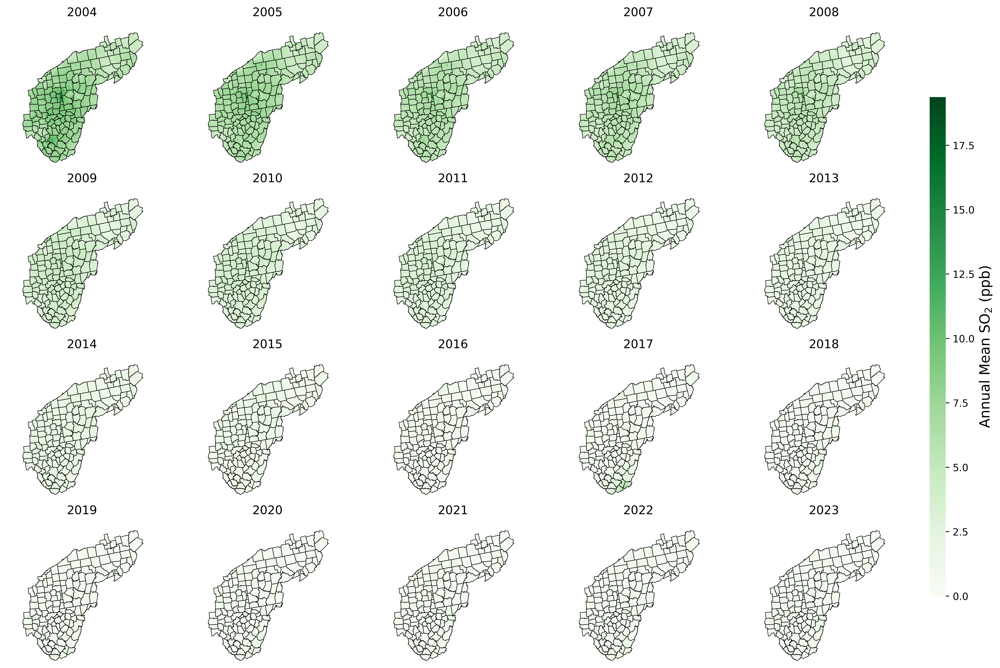

In [5]:
annual_so2 = so2_ds['prediction'].groupby('time.year').mean('time')  
ds = annual_so2.to_dataset(name='prediction')                       

grid_ds = xr.open_dataset(grid_path)
ds['Projected X'] = grid_ds['Projected X']
ds['Projected Y'] = grid_ds['Projected Y']
ds = ds.assign_coords({
    'Projected X': (('y','x'), ds['Projected X'].data),
    'Projected Y': (('y','x'), ds['Projected Y'].data)
})


years = ds['year'].values
ds = ds.rename(year='time')

fig = plt.figure(figsize=(15, 10), dpi=600)
gs = gridspec.GridSpec(nrows=4, ncols=5, figure=fig, wspace=0.1, hspace=0.15)


vmin = float(ds['prediction'].min())
vmax = float(ds['prediction'].max())

for i, year in enumerate(years):
    row, col = divmod(i, 5)
    ax = fig.add_subplot(gs[row, col])

    im = ds['prediction'].sel(time=year).plot(
        ax=ax, x='Projected X', y='Projected Y',
        cmap='Greens', vmin=vmin, vmax=vmax, add_colorbar=False
    )
    study_area.plot(ax=ax, facecolor='none', edgecolor='k', linewidth=0.5)
    ax.set_title(str(int(year)), fontsize=12, pad=2)
    ax.axis('off')

cbar_ax = fig.add_axes([0.92, 0.15, 0.015, 0.7])
cbar = fig.colorbar(im, cax=cbar_ax)
cbar.set_label(r'Annual Mean SO$_2$ (ppb)', fontsize=14)  
cbar.outline.set_visible(False)

plt.subplots_adjust(left=0.05, right=0.9, top=0.96, bottom=0.06)
plt.show()

# Time series

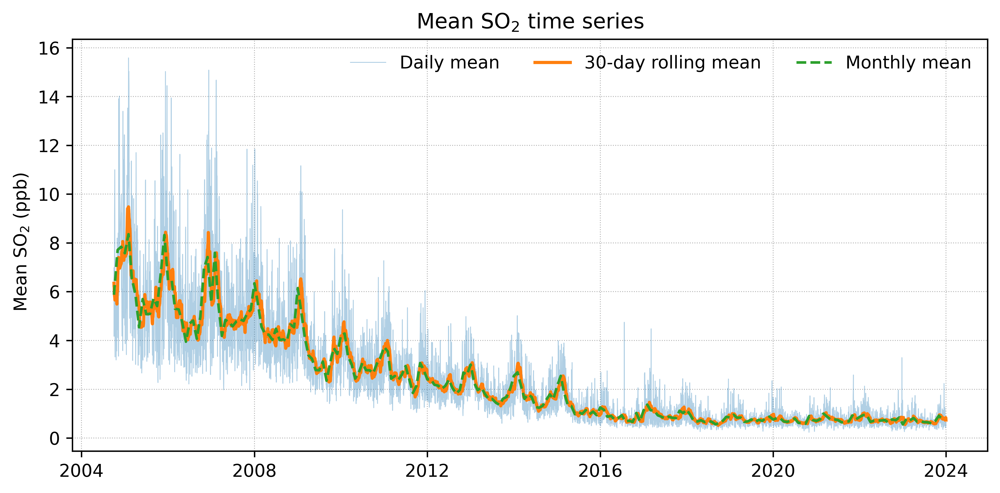

In [6]:
daily = so2_ds['prediction'].mean(('y','x'), skipna=True).to_series()
daily = daily.sort_index()

roll30 = daily.rolling(30, center=True, min_periods=15).mean()
monthly = daily.resample('MS').mean()

fig, ax = plt.subplots(figsize=(8, 4), dpi=600)
ax.plot(daily.index, daily.values, linewidth=0.5, alpha=0.35, label='Daily mean')
ax.plot(roll30.index, roll30.values, linewidth=1.8, label='30-day rolling mean')
ax.plot(monthly.index, monthly.values, linewidth=1.5, linestyle='--', label='Monthly mean')

ax.set_ylabel(' Mean SO$_2$ (ppb)')   
ax.set_title('Mean SO$_2$ time series')
ax.grid(True, linestyle=':', linewidth=0.5)
ax.legend(frameon=False, ncol=4, loc='upper right')
plt.tight_layout()
plt.show()

# Seasonal mean

In [8]:
seasonal_list = []
years = np.unique(so2_ds['time'].dt.year.values)
for y in years:
    sub = so2_ds.sel(time=str(y))
    seas = sub.groupby('time.season').mean('time')  
    seas = seas.assign_coords(year=y)
    seasonal_list.append(seas)

seasonal_by_year = xr.concat(seasonal_list, dim='year').transpose('season','year','y','x')

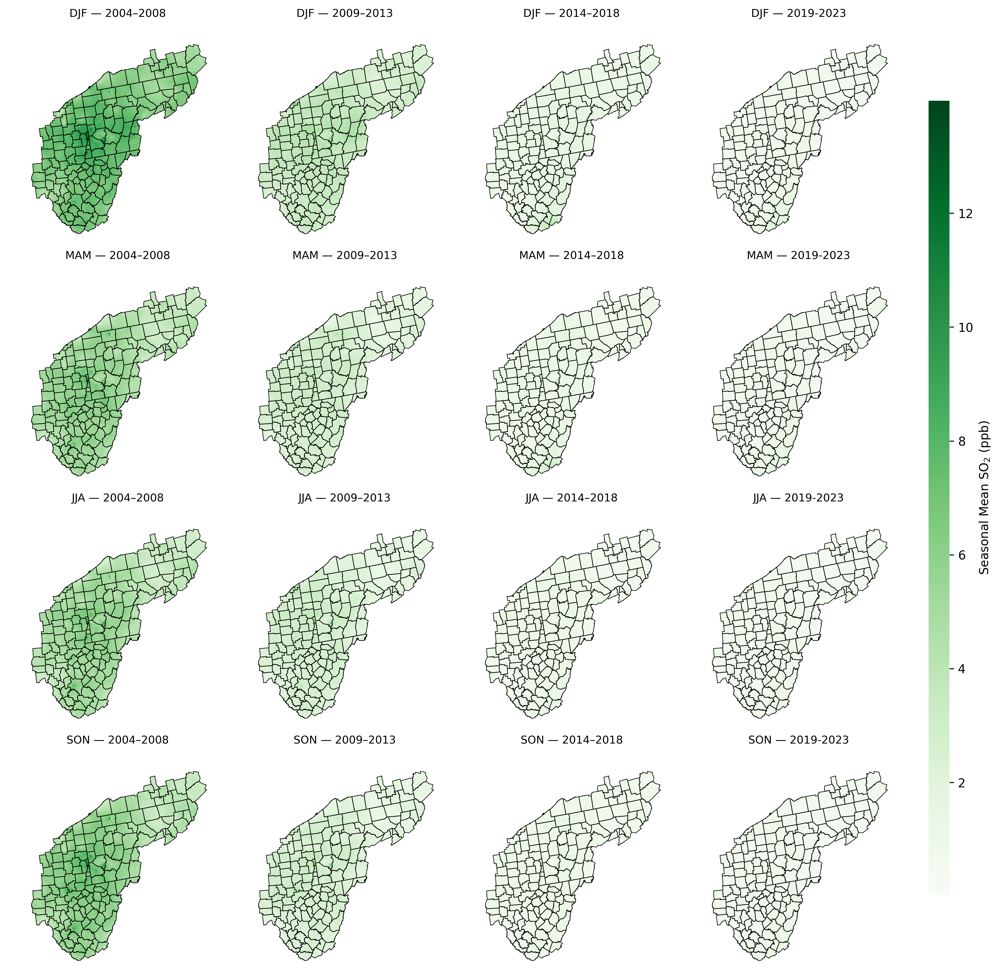

In [9]:
windows = {
    '2004–2008': (2004, 2008),
    '2009–2013':   (2009, 2013),
    '2014–2018':  (2014, 2018),
    '2019-2023':(2019, 2023)
    
}
seasons_order = ['DJF','MAM','JJA','SON']

win_means = {}
for label, (y0,y1) in windows.items():
    win_means[label] = seasonal_by_year.sel(year=slice(y0,y1)).mean('year')  

stack_for_scale = xr.concat([win_means[k]['prediction'] for k in win_means], dim='season')
vmin = float(stack_for_scale.min())
vmax = float(stack_for_scale.max())

fig = plt.figure(figsize=(12, 12), dpi=300)
gs = gridspec.GridSpec(nrows=4, ncols=4, figure=fig, wspace=0.04, hspace=0.08)
for r, s in enumerate(seasons_order):
    for c, label in enumerate(windows.keys()):
        ax = fig.add_subplot(gs[r, c])
        im = win_means[label]['prediction'].sel(season=s).plot(
            ax=ax, x='Projected X', y='Projected Y',
            cmap='Greens', vmin=vmin, vmax=vmax, add_colorbar=False
        )
        study_area.plot(ax=ax, facecolor='none', edgecolor='k', linewidth=0.5)
        ax.set_title(f'{s} — {label}', fontsize=9)
        ax.axis('off')

cax = fig.add_axes([0.92, 0.12, 0.02, 0.76])
cbar = fig.colorbar(im, cax=cax)
cbar.set_label(r'Seasonal Mean SO$_{2}$ (ppb)')
cbar.outline.set_visible(False)
plt.subplots_adjust(left=0.04, right=0.9, top=0.96, bottom=0.05)
plt.show()

# Daily maps

Selected dates by window:
 2004–2008 — Low (5th)    : 2006-05-14
 2004–2008 — Median (50th): 2006-08-10
 2004–2008 — High (95th)  : 2005-12-18
 2009–2013 — Low (5th)    : 2013-06-03
 2009–2013 — Median (50th): 2009-07-18
 2009–2013 — High (95th)  : 2009-02-18
 2014–2018 — Low (5th)    : 2016-05-01
 2014–2018 — Median (50th): 2017-04-13
 2014–2018 — High (95th)  : 2015-02-01
 2019-2023 — Low (5th)    : 2019-08-23
 2019-2023 — Median (50th): 2021-01-09
 2019-2023 — High (95th)  : 2023-10-25


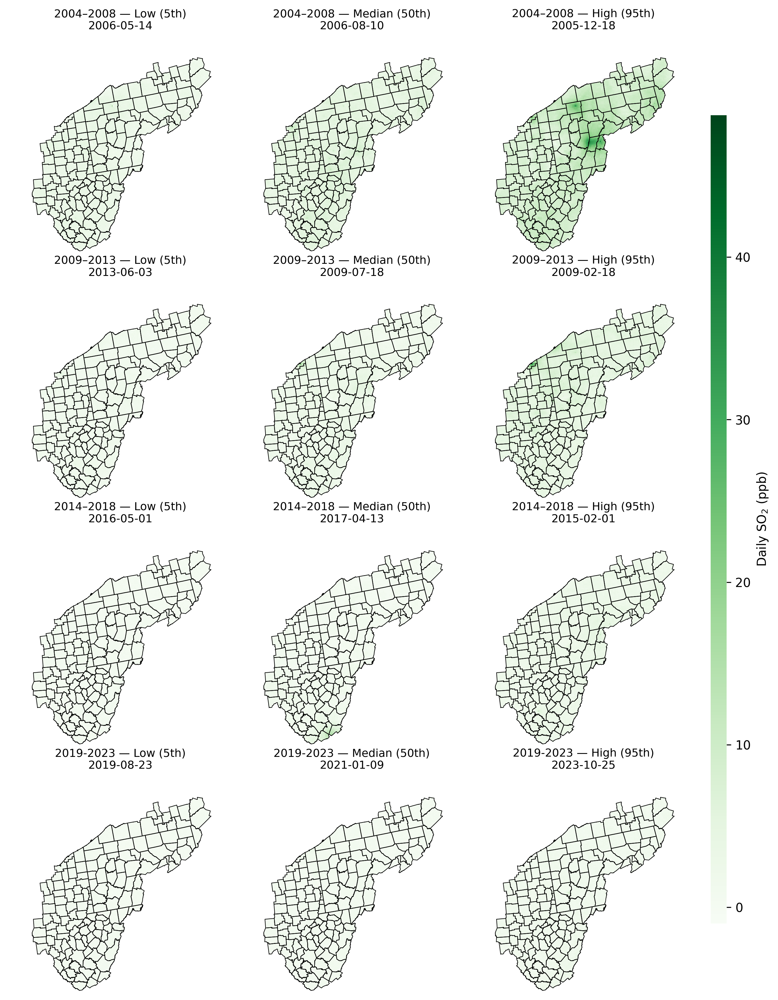

In [10]:
series = so2_ds['prediction'].mean(('y','x'), skipna=True).to_series()

def pick_three(s: pd.Series):
    q = s.quantile([0.05, 0.50, 0.95]).to_dict()
    return [
        ('Low (5th)',     (s - q[0.05]).abs().idxmin()),
        ('Median (50th)', (s - q[0.50]).abs().idxmin()),
        ('High (95th)',   (s - q[0.95]).abs().idxmin()),
    ]

window_picks = {}
for label, (y0, y1) in windows.items():
    sub = series.loc[f'{y0}-01-01': f'{y1}-12-31']
    if len(sub) == 0: 
        continue
    window_picks[label] = pick_three(sub)

print("Selected dates by window:")
for label, triples in window_picks.items():
    for tlabel, dt in triples:
        print(f"{label:>10} — {tlabel:<13}: {pd.Timestamp(dt).date()}")

all_times = [dt for triples in window_picks.values() for _, dt in triples]
subset = so2_ds.sel(time=sorted(all_times))
vmin = float(subset['prediction'].min())
vmax = float(subset['prediction'].max())

fig = plt.figure(figsize=(9, 12), dpi=300)
gs = gridspec.GridSpec(nrows=4, ncols=3, figure=fig, wspace=0.04, hspace=0.08)
col_labels = ['Low (5th)', 'Median (50th)', 'High (95th)']
row_labels = list(windows.keys())

for r, win_label in enumerate(row_labels):
    triples = dict(window_picks[win_label])
    for c, clabel in enumerate(col_labels):
        t = triples[clabel]
        ax = fig.add_subplot(gs[r, c])
        im = so2_ds['prediction'].sel(time=t).plot(
            ax=ax, x='Projected X', y='Projected Y',
            cmap='Greens', vmin=vmin, vmax=vmax, add_colorbar=False
        )
        try:
            study_area.plot(ax=ax, facecolor='none', edgecolor='k', linewidth=0.5)
        except NameError:
            pass
        ax.set_title(f"{win_label} — {clabel}\n{pd.Timestamp(t).date()}", fontsize=9)
        ax.axis('off')

cax = fig.add_axes([0.92, 0.12, 0.02, 0.76])
cbar = plt.colorbar(im, cax=cax)
cbar.set_label(r'Daily SO$_{2}$ (ppb)')
cbar.outline.set_visible(False)

plt.subplots_adjust(left=0.04, right=0.9, top=0.96, bottom=0.05)
plt.show()